# Air Quality Index (AQI) Prediction from Pollutant Levels Using Machine Learning

**Dataset:** Air Quality Data in India (Kaggle) - `city_day.csv`
**Objective:** Predict AQI from pollutant concentrations (PM2.5, PM10, NO2, NOx, NH3, CO, SO2, O3) using four regression algorithms: Simple Linear, Multiple Linear, Polynomial (degree 2) and Decision Tree.

**Leakage-safe workflow used in this notebook:**
1. Clean rows (duplicates, missing target, infinite values)
2. Split 80:20
3. Fit imputer, outlier limits, feature selection and scalers on the **training set only**
4. Apply the same fitted steps to the test set

## 1. Dataset Loading
Run the cell and upload the `city_day.csv` file you downloaded from Kaggle.

In [4]:
import io
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from google.colab import files

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
pd.set_option("display.max_columns", 50)

In [5]:
!pip install -q kagglehub

import os
import pandas as pd
import kagglehub

path = kagglehub.dataset_download("rohanrao/air-quality-data-in-india")
print("Path to dataset files:", path)
print("Files:", os.listdir(path))

file_name = "city_day.csv"
df = pd.read_csv(os.path.join(path, file_name))

print("\nFile loaded:", file_name)
print("Shape:", df.shape)
print("\nColumn names:", list(df.columns))
print("\nFirst five records:")
display(df.head())
print("\nData types:")
print(df.dtypes)

Using Colab cache for faster access to the 'air-quality-data-in-india' dataset.
Path to dataset files: /kaggle/input/air-quality-data-in-india
Files: ['stations.csv', 'station_hour.csv', 'city_day.csv', 'city_hour.csv', 'station_day.csv']

File loaded: city_day.csv
Shape: (29531, 16)

Column names: ['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']

First five records:


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN



Data types:
City           object
Date           object
PM2.5         float64
PM10          float64
NO            float64
NO2           float64
NOx           float64
NH3           float64
CO            float64
SO2           float64
O3            float64
Benzene       float64
Toluene       float64
Xylene        float64
AQI           float64
AQI_Bucket     object
dtype: object


## 2. Data Preprocessing

**Decisions made:**
- `AQI_Bucket` is removed because it is derived from AQI (target leakage).
- `City` is **not** used as an input feature, because the goal is to predict AQI directly from pollutant levels. So no encoding is needed.
- `NO`, `Benzene`, `Toluene` and `Xylene` are not in the objective's pollutant list and have many missing values, so they are dropped.
- Rows with no `AQI` value cannot be used for supervised learning and are removed.

In [6]:
print("Missing values per column:")
missing = pd.DataFrame({"Missing": df.isnull().sum(), "Percent": (df.isnull().mean() * 100).round(2)})
display(missing)
print("Duplicate records:", df.duplicated().sum())

Missing values per column:


,Missing,Percent
City,0,0.00
Date,0,0.00
PM2.5,4598,15.57
PM10,11140,37.72
NO,3582,12.13
NO2,3585,12.14
NOx,4185,14.17
NH3,10328,34.97
CO,2059,6.97
SO2,3854,13.05


Duplicate records: 0


In [7]:
pollutants = ["PM2.5", "PM10", "NO2", "NOx", "NH3", "CO", "SO2", "O3"]

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())

df = df.drop_duplicates()
df = df.drop(columns=["AQI_Bucket", "City", "NO", "Benzene", "Toluene", "Xylene"], errors="ignore")
df[pollutants + ["AQI"]] = df[pollutants + ["AQI"]].replace([np.inf, -np.inf], np.nan)

print("Rows before cleaning:", len(df))
df = df.dropna(subset=["AQI"])
df = df[df[pollutants].notnull().sum(axis=1) >= 4]
df = df.reset_index(drop=True)
print("Rows after removing missing AQI and rows with too few pollutant readings:", len(df))

Date range: 2015-01-01 to 2020-07-01
Rows before cleaning: 29531
Rows after removing missing AQI and rows with too few pollutant readings: 24782


In [8]:
X = df[pollutants]
y = df["AQI"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training set:", X_train.shape, "| Test set:", X_test.shape)

Training set: (19825, 8) | Test set: (4957, 8)


**Imputation and outlier handling** - the median and the outlier limits (Q1 - 3xIQR, Q3 + 3xIQR) are calculated from the training set only, then applied to both sets. Extreme values are capped (not deleted), so no rows are lost.

In [9]:
imputer = SimpleImputer(strategy="median")
imputer.fit(X_train)
X_train_imp = pd.DataFrame(imputer.transform(X_train), columns=pollutants, index=X_train.index)
X_test_imp = pd.DataFrame(imputer.transform(X_test), columns=pollutants, index=X_test.index)

q1, q3 = X_train_imp.quantile(0.25), X_train_imp.quantile(0.75)
iqr = q3 - q1
lower_limit = (q1 - 3 * iqr).clip(lower=0)
upper_limit = q3 + 3 * iqr

outlier_counts = ((X_train_imp < lower_limit) | (X_train_imp > upper_limit)).sum()
print("Outliers capped in training data (per feature):")
print(outlier_counts)

X_train_clean = X_train_imp.clip(lower=lower_limit, upper=upper_limit, axis=1)
X_test_clean = X_test_imp.clip(lower=lower_limit, upper=upper_limit, axis=1)

print("\nMissing values left in train/test:", X_train_clean.isnull().sum().sum(), "/", X_test_clean.isnull().sum().sum())

Outliers capped in training data (per feature):
PM2.5     588
PM10      905
NO2       214
NOx       560
NH3       667
CO       1327
SO2      1113
O3         72
dtype: int64

Missing values left in train/test: 0 / 0


**Scaling** is done with `StandardScaler` inside each model pipeline (Section 5). A pipeline fits the scaler on the training data only, so no test information leaks into training.

## 3. Exploratory Data Analysis (EDA)
EDA is performed on the training data only, so the test set stays unseen.

In [10]:
train_eda = X_train_clean.copy()
train_eda["AQI"] = y_train

print("Descriptive statistics:")
display(train_eda.describe().T.round(2))

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
PM2.5,19825.0,64.94,52.21,0.04,29.61,49.06,80.12,231.65
PM10,19825.0,108.61,61.65,0.03,72.03,96.67,124.17,280.59
NO2,19825.0,28.63,22.50,0.01,12.17,22.27,38.09,115.85
NOx,19825.0,30.73,25.45,0.00,14.06,23.74,38.44,111.58
NH3,19825.0,20.44,14.84,0.01,11.30,16.41,24.83,65.42
CO,19825.0,1.23,1.02,0.00,0.59,0.93,1.47,4.11
SO2,19825.0,12.73,10.59,0.01,5.79,9.25,15.05,42.83
O3,19825.0,34.74,20.96,0.01,19.66,31.24,45.45,122.82
AQI,19825.0,166.92,141.94,13.00,81.00,118.00,209.00,2049.00


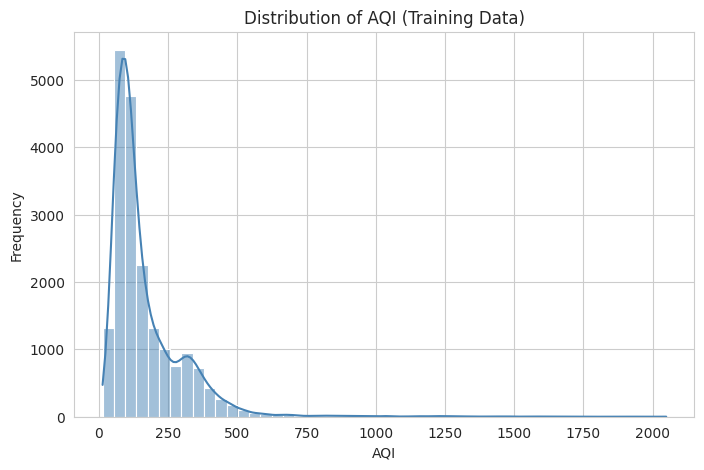

In [11]:
plt.figure(figsize=(8, 5))
sns.histplot(y_train, bins=50, kde=True, color="steelblue")
plt.title("Distribution of AQI (Training Data)")
plt.xlabel("AQI")
plt.ylabel("Frequency")
plt.show()

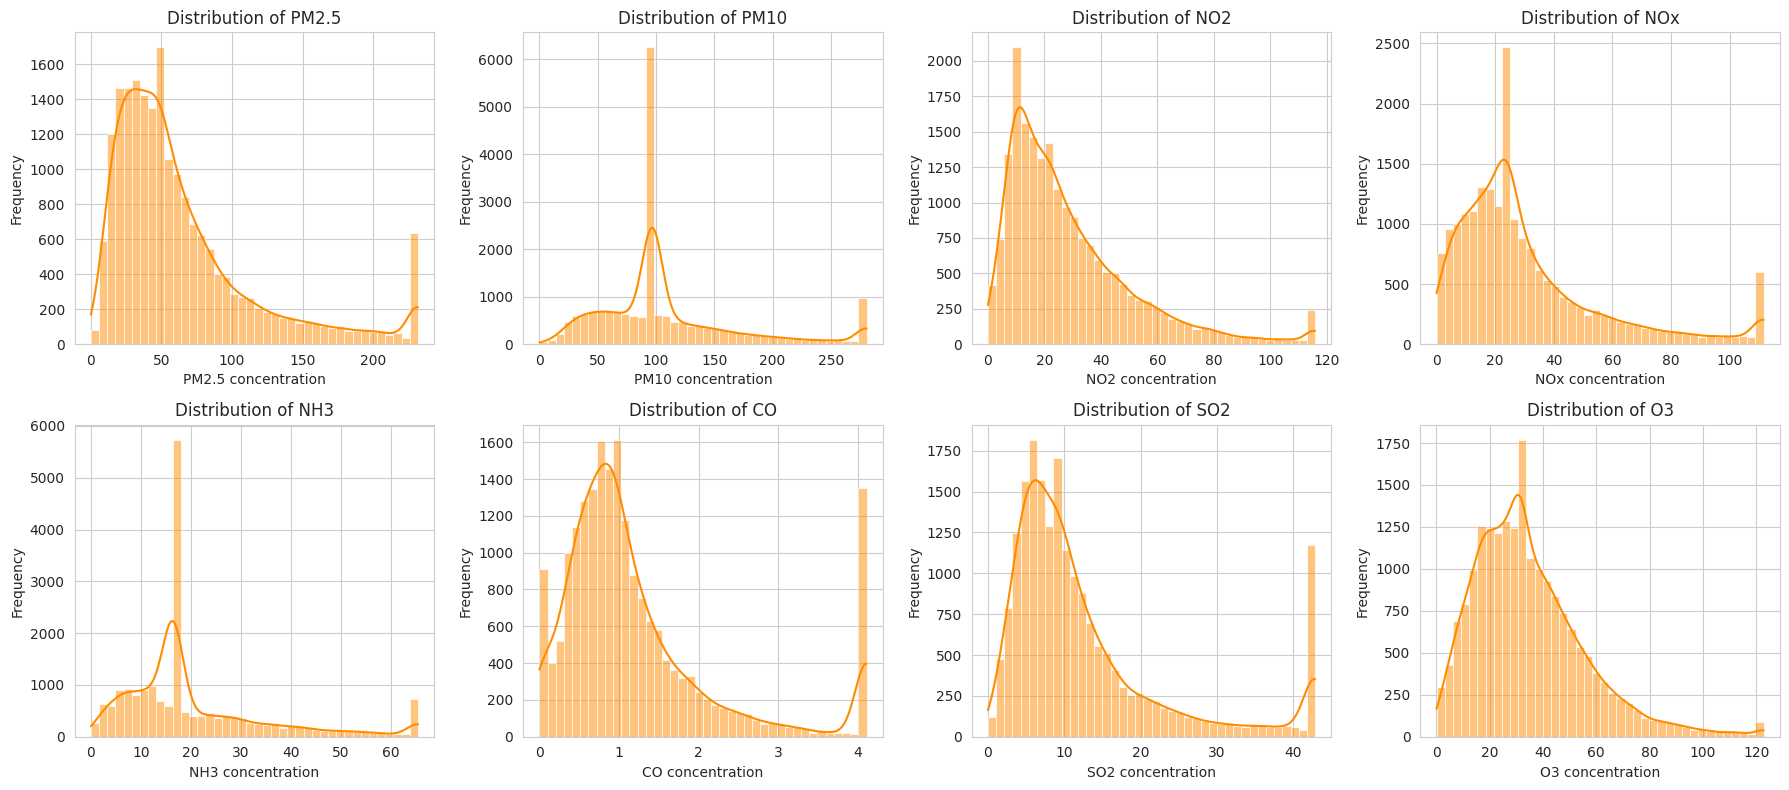

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), pollutants):
    sns.histplot(X_train_clean[col], bins=40, kde=True, ax=ax, color="darkorange")
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(f"{col} concentration")
    ax.set_ylabel("Frequency")
plt.tight_layout()
plt.show()

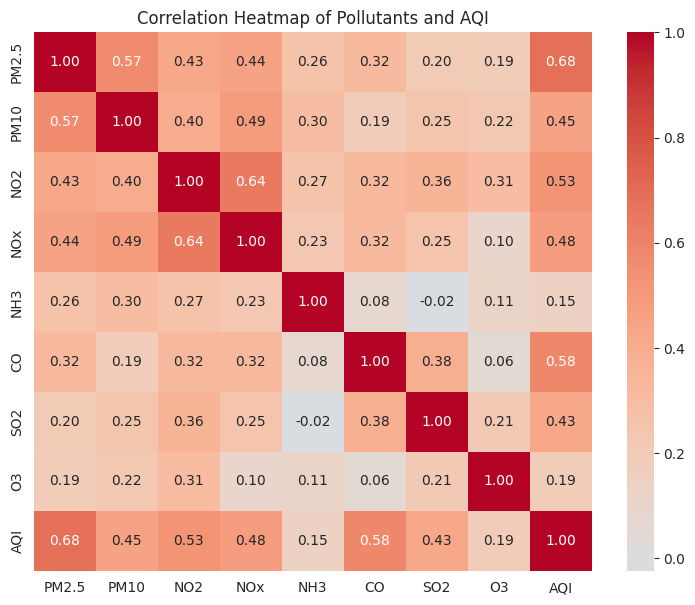

Correlation of each pollutant with AQI:
PM2.5    0.683
CO       0.580
NO2      0.526
NOx      0.478
PM10     0.445
SO2      0.430
O3       0.195
NH3      0.149
Name: AQI, dtype: float64

Most strongly correlated pollutants: ['PM2.5', 'CO', 'NO2']


In [13]:
plt.figure(figsize=(9, 7))
sns.heatmap(train_eda.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of Pollutants and AQI")
plt.show()

corr_with_aqi = train_eda.corr()["AQI"].drop("AQI").sort_values(ascending=False)
print("Correlation of each pollutant with AQI:")
print(corr_with_aqi.round(3))
print("\nMost strongly correlated pollutants:", list(corr_with_aqi.abs().sort_values(ascending=False).head(3).index))

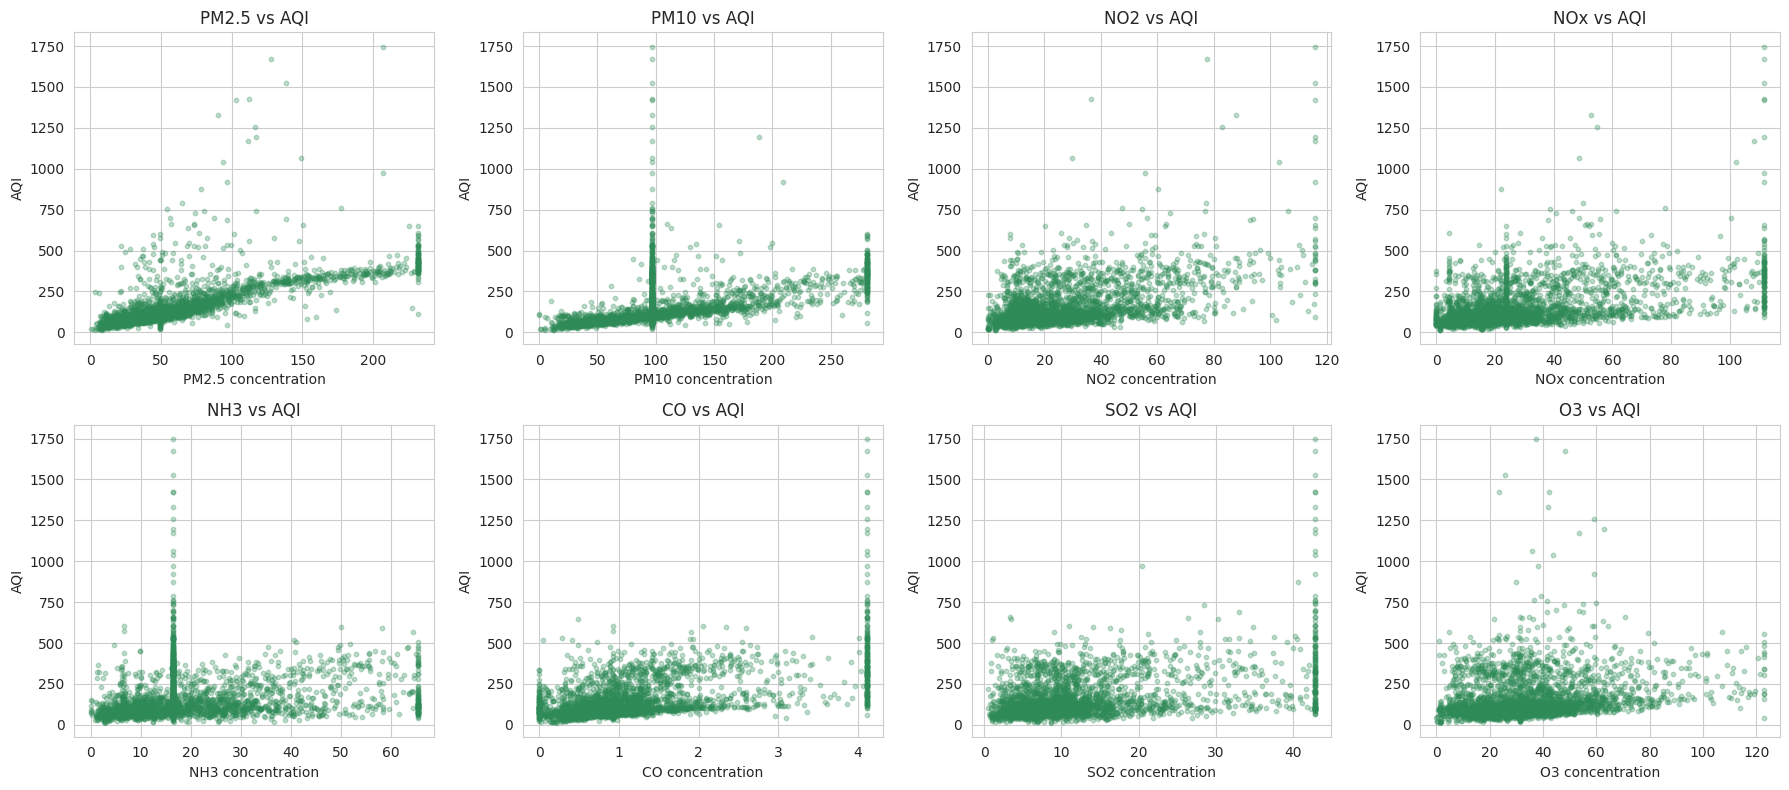

In [14]:
sample = train_eda.sample(n=min(3000, len(train_eda)), random_state=42)
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), pollutants):
    ax.scatter(sample[col], sample["AQI"], alpha=0.3, s=10, color="seagreen")
    ax.set_title(f"{col} vs AQI")
    ax.set_xlabel(f"{col} concentration")
    ax.set_ylabel("AQI")
plt.tight_layout()
plt.show()

## 4. Feature Selection
Features are chosen using correlation with AQI calculated on the **training data only**. Pollutants with an absolute correlation of at least 0.30 are selected.

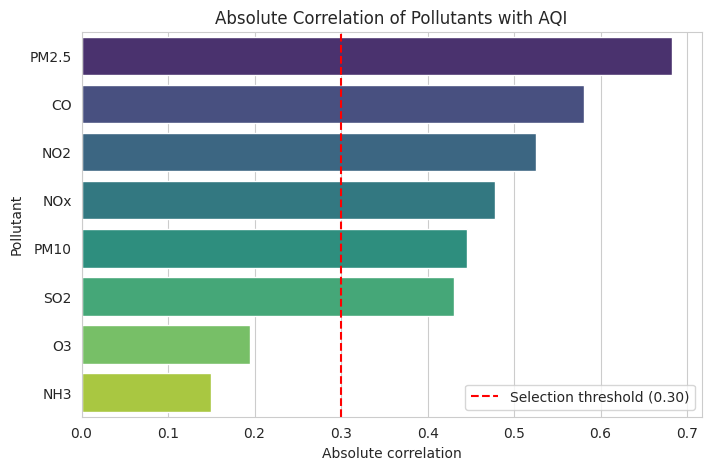

Final selected features: ['PM2.5', 'CO', 'NO2', 'NOx', 'PM10', 'SO2']
Feature used for Simple Linear Regression: PM2.5


In [15]:
corr_abs = corr_with_aqi.abs().sort_values(ascending=False)
selected_features = corr_abs[corr_abs >= 0.30].index.tolist()
if len(selected_features) < 3:
    selected_features = corr_abs.head(3).index.tolist()

simple_feature = corr_abs.index[0]

plt.figure(figsize=(8, 5))
sns.barplot(x=corr_abs.values, y=corr_abs.index, palette="viridis")
plt.axvline(0.30, color="red", linestyle="--", label="Selection threshold (0.30)")
plt.title("Absolute Correlation of Pollutants with AQI")
plt.xlabel("Absolute correlation")
plt.ylabel("Pollutant")
plt.legend()
plt.show()

print("Final selected features:", selected_features)
print("Feature used for Simple Linear Regression:", simple_feature)

## 5. Model Training
All models use the same training and test split.

In [16]:
def get_data(features):
    return X_train_clean[features], X_test_clean[features]

models = {}

### A. Simple Linear Regression

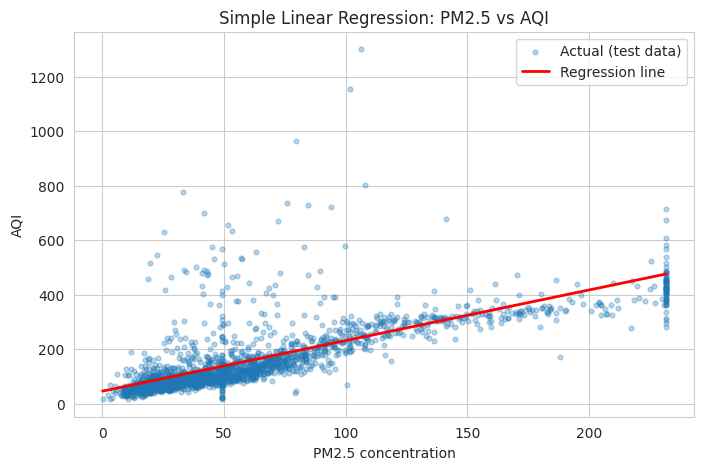

Sample predictions:


,Actual AQI,Predicted AQI
0,79.0,122.4
1,51.0,84.9
2,152.0,139.9
3,51.0,100.4
4,163.0,193.4
5,208.0,162.5
6,50.0,75.3
7,215.0,175.8
8,107.0,98.3
9,62.0,73.5


In [17]:
Xtr_s, Xte_s = get_data([simple_feature])

slr = Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())])
slr.fit(Xtr_s, y_train)
models["Simple Linear Regression"] = (slr, [simple_feature])

line_x = pd.DataFrame({simple_feature: np.linspace(Xte_s[simple_feature].min(), Xte_s[simple_feature].max(), 200)})
plot_idx = Xte_s.sample(n=min(2000, len(Xte_s)), random_state=42).index

plt.figure(figsize=(8, 5))
plt.scatter(Xte_s.loc[plot_idx, simple_feature], y_test.loc[plot_idx], alpha=0.3, s=12, label="Actual (test data)")
plt.plot(line_x[simple_feature], slr.predict(line_x), color="red", linewidth=2, label="Regression line")
plt.title(f"Simple Linear Regression: {simple_feature} vs AQI")
plt.xlabel(f"{simple_feature} concentration")
plt.ylabel("AQI")
plt.legend()
plt.show()

preds = pd.DataFrame({"Actual AQI": y_test.values[:10], "Predicted AQI": slr.predict(Xte_s)[:10].round(1)})
print("Sample predictions:")
display(preds)

### B. Multiple Linear Regression

In [18]:
Xtr_m, Xte_m = get_data(selected_features)

mlr = Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())])
mlr.fit(Xtr_m, y_train)
models["Multiple Linear Regression"] = (mlr, selected_features)

scaler = mlr.named_steps["scaler"]
lin = mlr.named_steps["model"]
raw_coef = lin.coef_ / scaler.scale_
raw_intercept = lin.intercept_ - np.sum(lin.coef_ * scaler.mean_ / scaler.scale_)

coef_table = pd.DataFrame({
    "Feature": selected_features,
    "Coefficient (original units)": raw_coef.round(4),
    "Coefficient (standardized)": lin.coef_.round(4),
})
display(coef_table)
print("Intercept (original units):", round(raw_intercept, 4))

,Feature,Coefficient (original units),Coefficient (standardized)
0,PM2.5,1.2896,67.3244
1,CO,43.6851,44.4221
2,NO2,0.8976,20.1988
3,NOx,0.2050,5.2157
4,PM10,0.0062,0.3804
5,SO2,2.0660,21.8731


Intercept (original units): -29.3397


### C. Polynomial Regression (degree 2)
Polynomial features, scaling and Linear Regression are combined in one pipeline, so all steps are fitted on training data only.

In [19]:
poly = Pipeline([
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("scaler", StandardScaler()),
    ("model", LinearRegression()),
])
poly.fit(Xtr_m, y_train)
models["Polynomial Regression (degree 2)"] = (poly, selected_features)

print("Number of input features:", Xtr_m.shape[1])
print("Number of features after polynomial expansion:", poly.named_steps["poly"].n_output_features_)

Number of input features: 6
Number of features after polynomial expansion: 27


### D. Decision Tree Regressor
Overfitting is controlled by tuning `max_depth` and `min_samples_leaf` with 5-fold cross-validation on the training data.

Best parameters: {'max_depth': 8, 'min_samples_leaf': 10}
Train R2: 0.8676 | Test R2: 0.8277


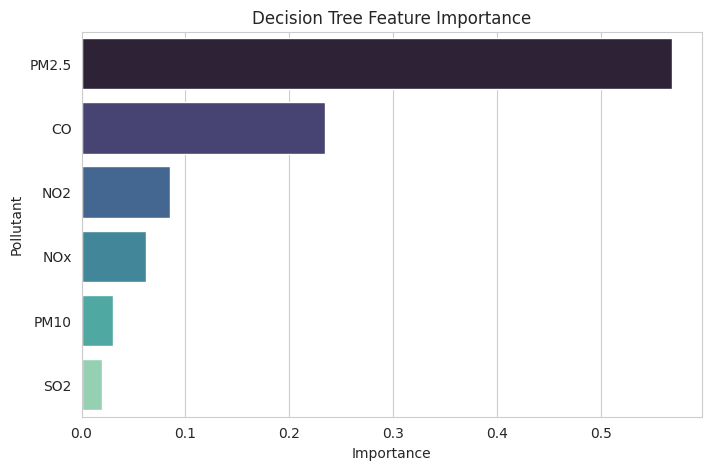

In [20]:
param_grid = {"max_depth": [4, 6, 8, 10, 12], "min_samples_leaf": [10, 20, 50]}
grid = GridSearchCV(DecisionTreeRegressor(random_state=42), param_grid, cv=5,
                    scoring="neg_root_mean_squared_error", n_jobs=-1)
grid.fit(Xtr_m, y_train)

tree = grid.best_estimator_
models["Decision Tree Regressor"] = (tree, selected_features)

print("Best parameters:", grid.best_params_)
print("Train R2:", round(tree.score(Xtr_m, y_train), 4), "| Test R2:", round(tree.score(Xte_m, y_test), 4))

importance = pd.Series(tree.feature_importances_, index=selected_features).sort_values(ascending=False)
plt.figure(figsize=(8, 5))
sns.barplot(x=importance.values, y=importance.index, palette="mako")
plt.title("Decision Tree Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Pollutant")
plt.show()

## 6. Model Evaluation

In [21]:
results = []
predictions = {}

for name, (model, feats) in models.items():
    pred = model.predict(X_test_clean[feats])
    predictions[name] = pred
    mse = mean_squared_error(y_test, pred)
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_test, pred),
        "Train R2": model.score(X_train_clean[feats], y_train),
    })

results_df = pd.DataFrame(results).set_index("Model").round(4)
print("Model Comparison Table (test set):")
display(results_df)

Model Comparison Table (test set):


,MAE,MSE,RMSE,R2,Train R2
Model,,,,,
Simple Linear Regression,47.0080,9668.7393,98.3297,0.4789,0.4659
Multiple Linear Regression,41.8636,5726.8826,75.6762,0.6913,0.6652
Polynomial Regression (degree 2),33.8526,3951.1347,62.8581,0.7870,0.7780
Decision Tree Regressor,27.1064,3195.7958,56.5314,0.8277,0.8676


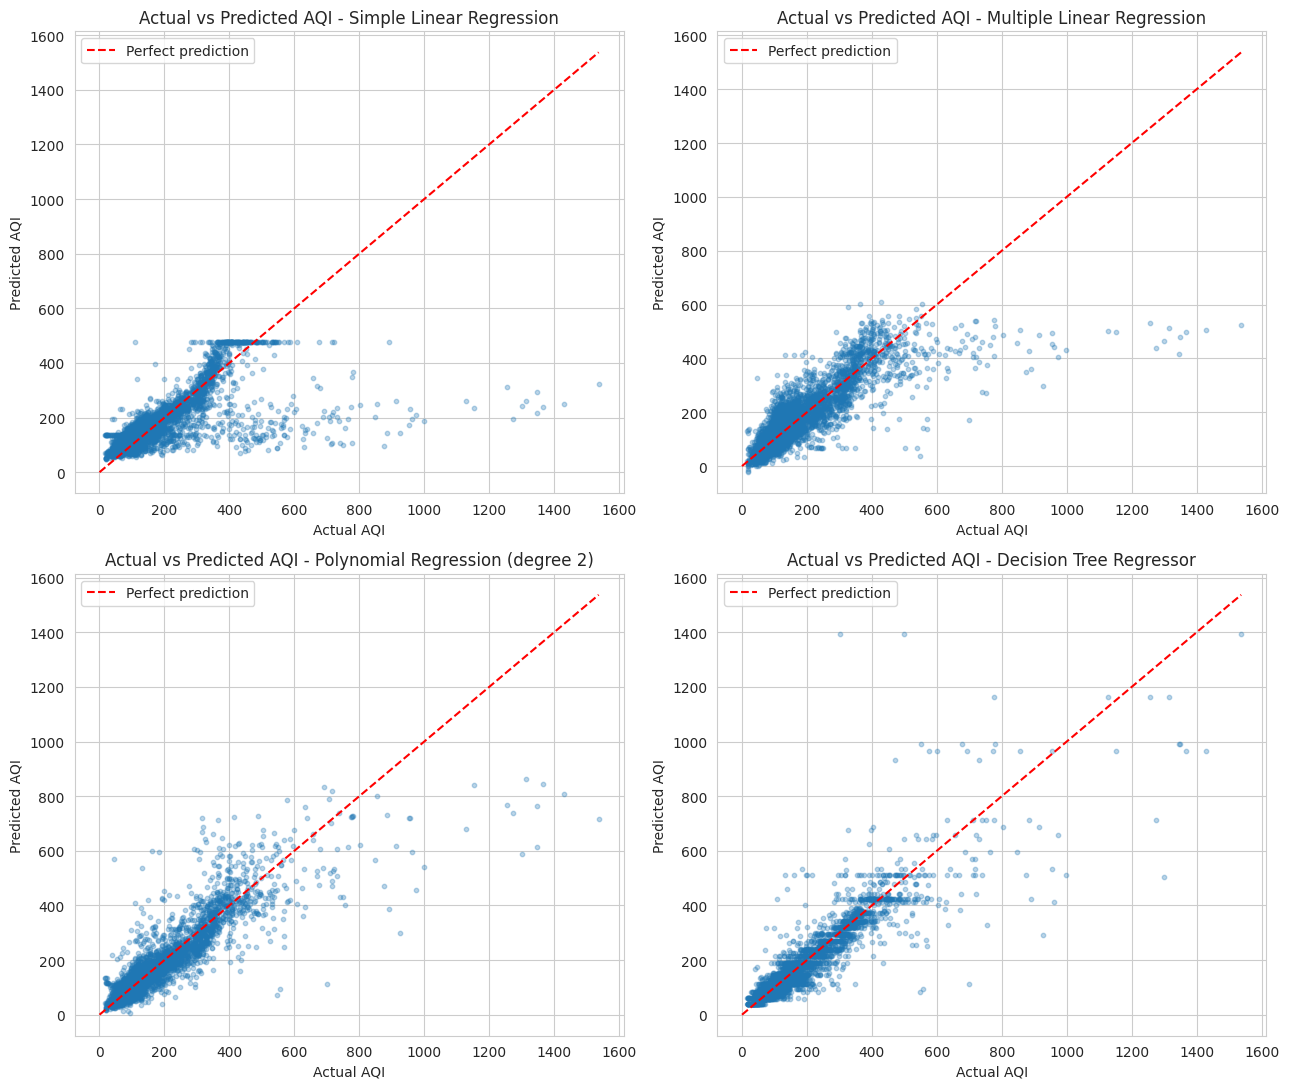

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(13, 11))
lims = [0, max(y_test.max(), max(p.max() for p in predictions.values()))]
for ax, (name, pred) in zip(axes.ravel(), predictions.items()):
    ax.scatter(y_test, pred, alpha=0.3, s=10)
    ax.plot(lims, lims, color="red", linestyle="--", label="Perfect prediction")
    ax.set_title(f"Actual vs Predicted AQI - {name}")
    ax.set_xlabel("Actual AQI")
    ax.set_ylabel("Predicted AQI")
    ax.legend()
plt.tight_layout()
plt.show()

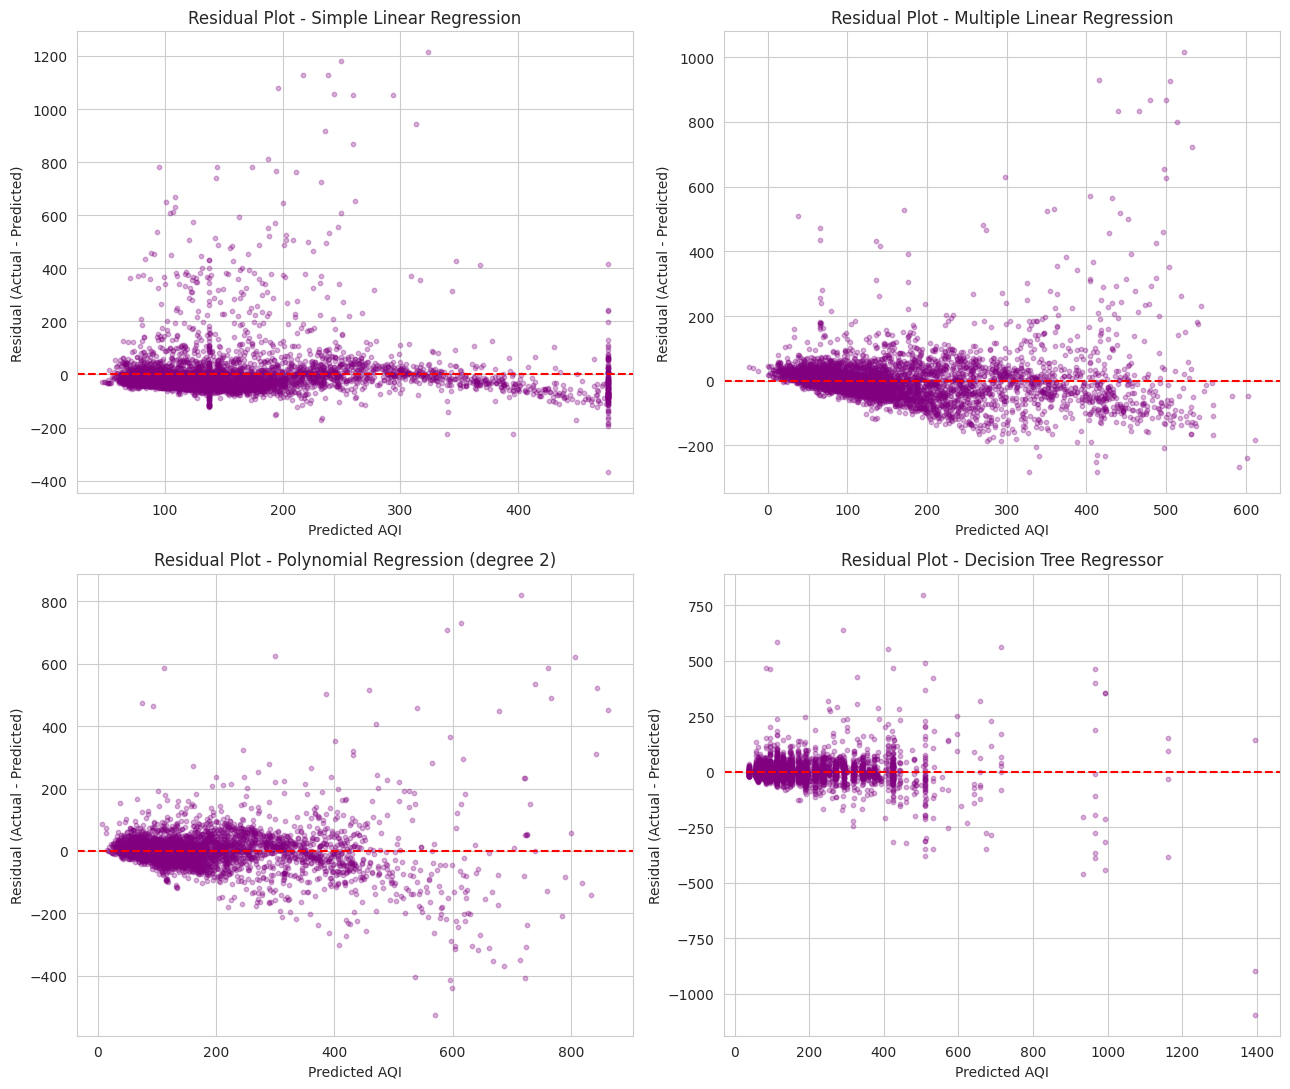

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for ax, (name, pred) in zip(axes.ravel(), predictions.items()):
    ax.scatter(pred, y_test - pred, alpha=0.3, s=10, color="purple")
    ax.axhline(0, color="red", linestyle="--")
    ax.set_title(f"Residual Plot - {name}")
    ax.set_xlabel("Predicted AQI")
    ax.set_ylabel("Residual (Actual - Predicted)")
plt.tight_layout()
plt.show()

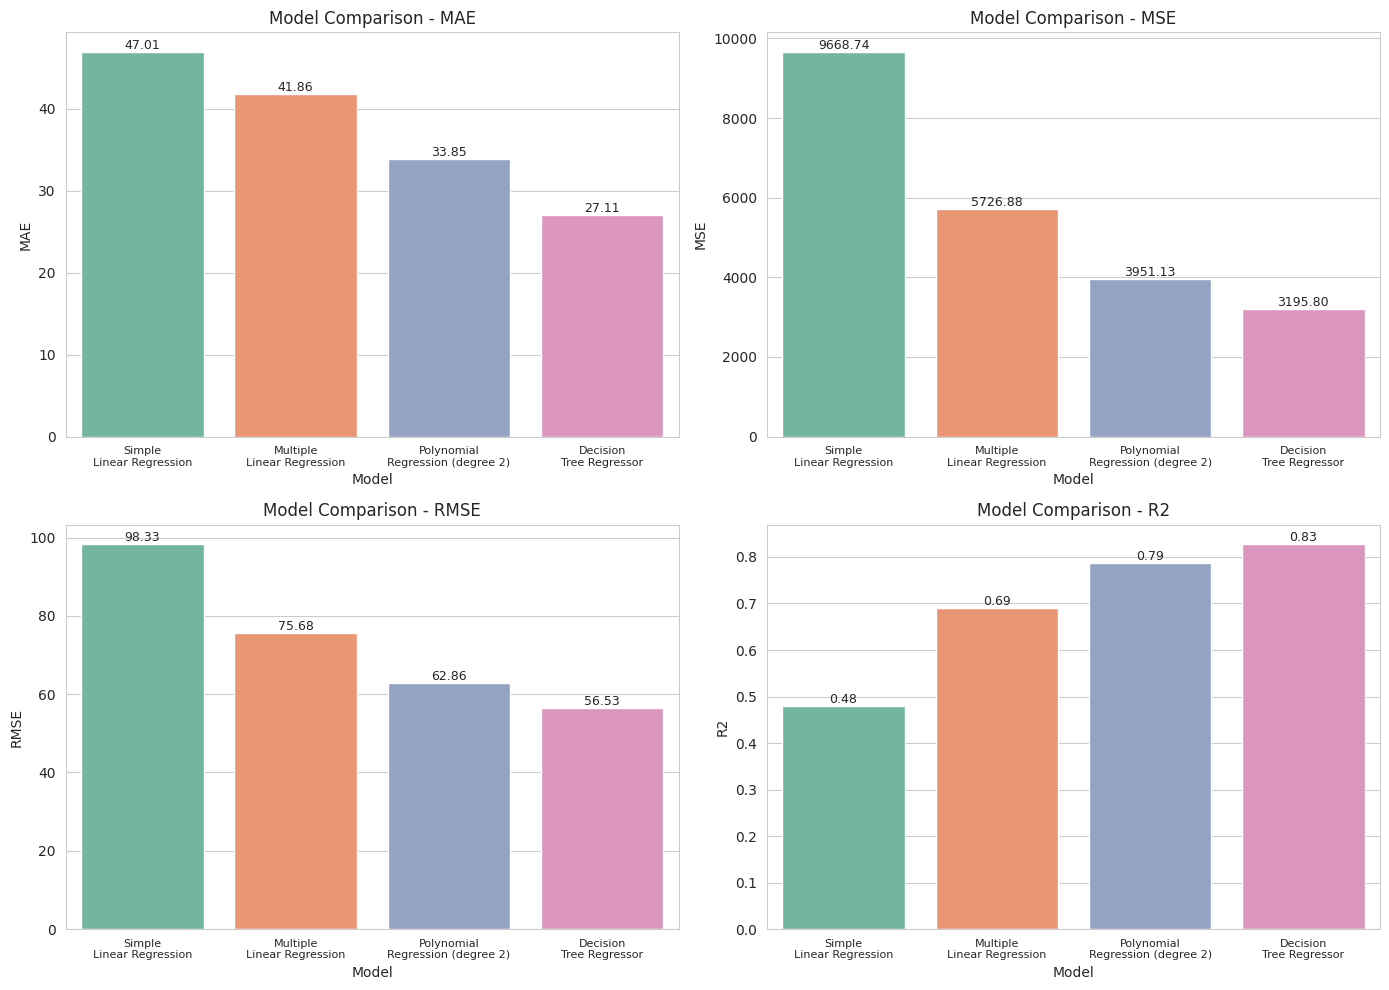

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, metric in zip(axes.ravel(), ["MAE", "MSE", "RMSE", "R2"]):
    sns.barplot(x=results_df.index, y=results_df[metric], palette="Set2", ax=ax)
    ax.set_title(f"Model Comparison - {metric}")
    ax.set_xlabel("Model")
    ax.set_ylabel(metric)
    ax.set_xticklabels([n.replace(" ", "\n", 1) for n in results_df.index], fontsize=8)
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

### What the metrics indicate
- **MAE** - average size of the prediction error in AQI units. Lower is better and it is easy to interpret.
- **MSE** - average of squared errors. It penalizes large errors heavily, so it is sensitive to outliers.
- **RMSE** - square root of MSE, in AQI units. It shows the typical error, with extra weight on large mistakes.
- **R2 Score** - share of AQI variation explained by the model. 1 is perfect and 0 means no better than predicting the mean.
- **Residual plots** - points should scatter randomly around zero. Curves or funnels suggest the model misses patterns.
- **Train R2 vs Test R2** - a large gap indicates overfitting.

## 7. Final Results

In [25]:
best_model_name = results_df["RMSE"].idxmin()
best_model, best_features = models[best_model_name]

print("Best-performing model (lowest RMSE):", best_model_name)
print("\nPerformance of all four algorithms:")
display(results_df.sort_values("RMSE"))
print("Final evaluation metrics of the best model:")
print(results_df.loc[best_model_name, ["MAE", "MSE", "RMSE", "R2"]])

Best-performing model (lowest RMSE): Decision Tree Regressor

Performance of all four algorithms:


,MAE,MSE,RMSE,R2,Train R2
Model,,,,,
Decision Tree Regressor,27.1064,3195.7958,56.5314,0.8277,0.8676
Polynomial Regression (degree 2),33.8526,3951.1347,62.8581,0.7870,0.7780
Multiple Linear Regression,41.8636,5726.8826,75.6762,0.6913,0.6652
Simple Linear Regression,47.0080,9668.7393,98.3297,0.4789,0.4659


Final evaluation metrics of the best model:
MAE       27.1064
MSE     3195.7958
RMSE      56.5314
R2         0.8277
Name: Decision Tree Regressor, dtype: float64


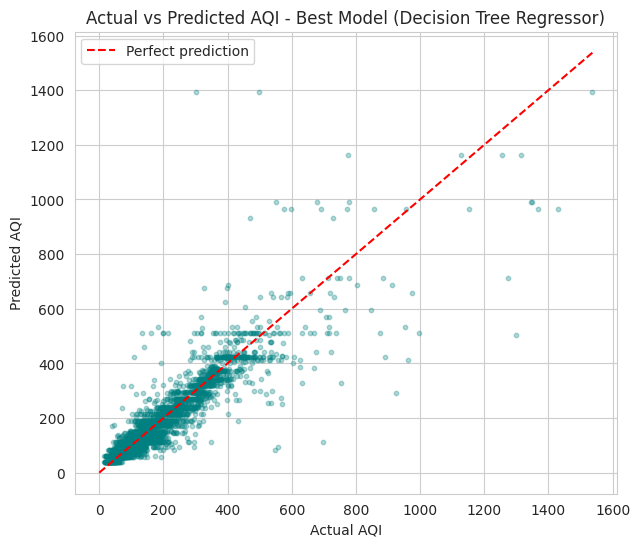

In [26]:
best_pred = predictions[best_model_name]

plt.figure(figsize=(7, 6))
plt.scatter(y_test, best_pred, alpha=0.3, s=10, color="teal")
plt.plot([0, y_test.max()], [0, y_test.max()], color="red", linestyle="--", label="Perfect prediction")
plt.title(f"Actual vs Predicted AQI - Best Model ({best_model_name})")
plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.legend()
plt.show()

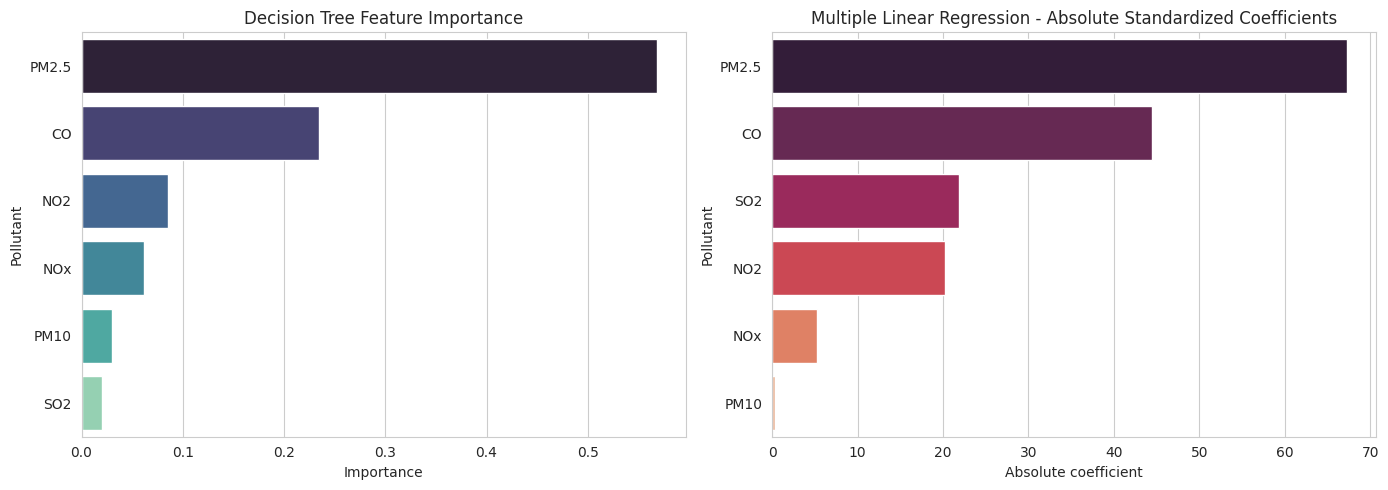

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(x=importance.values, y=importance.index, palette="mako", ax=axes[0])
axes[0].set_title("Decision Tree Feature Importance")
axes[0].set_xlabel("Importance")
axes[0].set_ylabel("Pollutant")

std_coef = pd.Series(np.abs(lin.coef_), index=selected_features).sort_values(ascending=False)
sns.barplot(x=std_coef.values, y=std_coef.index, palette="rocket", ax=axes[1])
axes[1].set_title("Multiple Linear Regression - Absolute Standardized Coefficients")
axes[1].set_xlabel("Absolute coefficient")
axes[1].set_ylabel("Pollutant")

plt.tight_layout()
plt.show()

In [28]:
model_bundle = {
    "model": best_model,
    "model_name": best_model_name,
    "features": best_features,
    "all_pollutants": pollutants,
    "imputer": imputer,
    "lower_limit": lower_limit,
    "upper_limit": upper_limit,
}
joblib.dump(model_bundle, "best_aqi_model.joblib")
print("Saved best model:", best_model_name, "-> best_aqi_model.joblib")
files.download("best_aqi_model.joblib")

Saved best model: Decision Tree Regressor -> best_aqi_model.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:
def aqi_category(value):
    if value <= 50: return "Good"
    if value <= 100: return "Satisfactory"
    if value <= 200: return "Moderate"
    if value <= 300: return "Poor"
    if value <= 400: return "Very Poor"
    return "Severe"

def predict_aqi(sample_values, bundle):
    sample_df = pd.DataFrame([sample_values]).reindex(columns=bundle["all_pollutants"])
    imputed = pd.DataFrame(bundle["imputer"].transform(sample_df), columns=bundle["all_pollutants"])
    clipped = imputed.clip(lower=bundle["lower_limit"], upper=bundle["upper_limit"], axis=1)
    return float(bundle["model"].predict(clipped[bundle["features"]])[0])

loaded_bundle = joblib.load("best_aqi_model.joblib")

sample_values = {"PM2.5": 120, "PM10": 210, "NO2": 45, "NOx": 60, "NH3": 25, "CO": 1.2, "SO2": 15, "O3": 40}
predicted = predict_aqi(sample_values, loaded_bundle)

print("Sample pollutant values:", sample_values)
print(f"Predicted AQI: {predicted:.1f} ({aqi_category(predicted)})")

Sample pollutant values: {'PM2.5': 120, 'PM10': 210, 'NO2': 45, 'NOx': 60, 'NH3': 25, 'CO': 1.2, 'SO2': 15, 'O3': 40}
Predicted AQI: 271.0 (Poor)


## 8. Conclusion

In [30]:
best_r2 = results_df.loc[best_model_name, "R2"]
best_rmse = results_df.loc[best_model_name, "RMSE"]
best_mae = results_df.loc[best_model_name, "MAE"]
top_features = list(corr_abs.head(3).index)

print(f"""
CONCLUSION
----------
Objective : Predict the Air Quality Index (AQI) from pollutant concentrations using regression.
Dataset   : Air Quality Data in India ({file_name}), {len(df)} usable daily records after cleaning.
Algorithms: Simple Linear, Multiple Linear, Polynomial (degree 2) and Decision Tree regression.
Best model: {best_model_name} (R2 = {best_r2:.3f}, RMSE = {best_rmse:.2f}, MAE = {best_mae:.2f}).

Key findings:
- Pollutants most correlated with AQI: {', '.join(top_features)}.
- Selected features: {', '.join(selected_features)}.
- Imputation, outlier limits and scaling were learned from the training data only, so there is no data leakage.
- Simple Linear Regression R2 = {results_df.loc["Simple Linear Regression", "R2"]:.3f}, versus {best_r2:.3f} for the best model.

Practical application:
AQI can be estimated quickly from pollutant sensor readings, which supports public health alerts,
pollution monitoring and policy decisions when an official AQI value is not available.
""")


CONCLUSION
----------
Objective : Predict the Air Quality Index (AQI) from pollutant concentrations using regression.
Dataset   : Air Quality Data in India (city_day.csv), 24782 usable daily records after cleaning.
Algorithms: Simple Linear, Multiple Linear, Polynomial (degree 2) and Decision Tree regression.
Best model: Decision Tree Regressor (R2 = 0.828, RMSE = 56.53, MAE = 27.11).

Key findings:
- Pollutants most correlated with AQI: PM2.5, CO, NO2.
- Selected features: PM2.5, CO, NO2, NOx, PM10, SO2.
- Imputation, outlier limits and scaling were learned from the training data only, so there is no data leakage.
- Simple Linear Regression R2 = 0.479, versus 0.828 for the best model.

Practical application:
AQI can be estimated quickly from pollutant sensor readings, which supports public health alerts,
pollution monitoring and policy decisions when an official AQI value is not available.

